# Performance Tear Sheet (one-page report)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

A one-page report that combines the charts and statistics an investor checks first: headline metrics, growth of $1 against a benchmark, drawdowns, rolling risk, a monthly-returns calendar and calendar-year returns. Return, risk and consistency read together, so no single flattering number tells the story alone.

## When to use

- Summarise a fund, strategy, or portfolio's track record on one page
- Compare a strategy with its benchmark across return, risk and consistency
- Produce a repeatable monthly or quarterly performance report from a price file

## Avoid when

- The history is short (under ~2 years); rolling and calendar panels become noise
- The audience needs one message (show the single relevant chart instead)
- Returns are not time-weighted (cash flows distort them; compute TWR first)

## Alternatives

- Cumulative return vs. benchmark (just the growth line)
- Drawdown (underwater) chart
- Monthly returns heatmap

## Design tips

- Always show the benchmark; absolute returns without context mislead
- Put growth on a log scale so equal percentage moves look equal across the history
- Report risk (volatility, max drawdown) next to return, never return alone
- Reusable: `from vizlib.finance import tear_sheet` or run `python -m vizlib.finance prices.csv --price Fund --benchmark Index`

## Example

Simulated daily returns for a fund and its benchmark index over seven years, including a sharp crash and a slow bear market. The report comes from the reusable `vizlib.finance.tear_sheet()` function.

### Setup

In [1]:
import sys
from pathlib import Path
# This example uses the reusable vizlib package from this repository
# (or `pip install -e .` at the repo root).
sys.path.insert(0, str(Path(".").resolve().parents[1]))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from vizlib.finance import tear_sheet, summary_stats

### Data

In [2]:
rng = np.random.default_rng(41)
dates = pd.bdate_range("2018-01-01", "2024-12-31")
n = len(dates)
# Market: calm drift, a sharp crash (~day 560) and a slow bear market (~day 1200).
market = rng.standard_t(4, n) * 0.007 + 0.0005
market[555:575] -= 0.010
market[1180:1380] -= 0.0008
# Fund: beta 0.85 to the market plus a small, noisy alpha.
fund = 0.85 * market + rng.normal(0.00012, 0.004, n)
returns = pd.Series(fund, index=dates, name="Fund")
benchmark = pd.Series(market, index=dates, name="Index")
title = "Global Equity Fund: performance report (simulated)"
summary_stats(returns, benchmark).style.format("{:.3f}")

,Fund,Index
Total return,1.351,0.815
CAGR,0.125,0.086
Volatility (ann.),0.139,0.144
Sharpe,0.917,0.643
Sortino,1.385,0.974
Max drawdown,-0.339,-0.385
Calmar,0.370,0.222
VaR 95% (1 period),-0.013,-0.013
CVaR 95% (1 period),-0.018,-0.019
Best period,0.046,0.056


### Plot

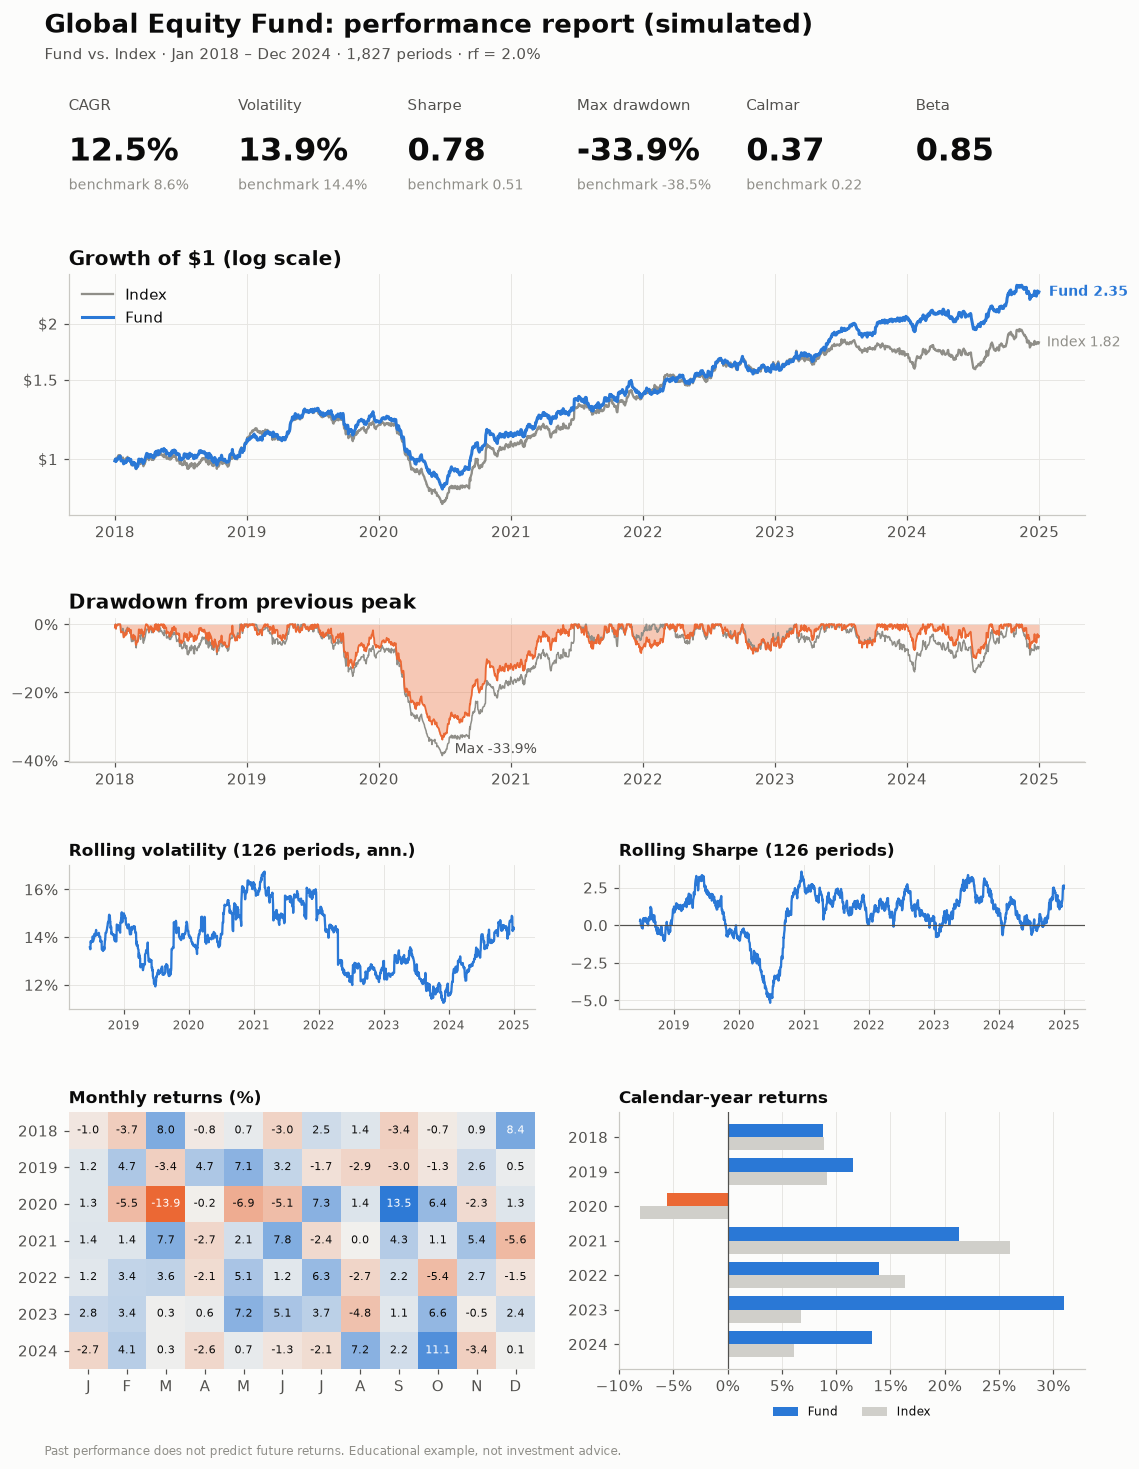

In [3]:
fig = tear_sheet(returns, benchmark, title=title, rf=0.02)
plt.show()

## How to read it

Start with the headline tiles: the fund earned a higher CAGR than the benchmark with lower volatility (beta below 1) and a shallower maximum drawdown. The growth panel shows where the gap opened, the drawdown panel shows how deep and how long each loss was, and the calendar shows how consistent the months were. Blue is a gain and orange a loss.

## Try it with real data

**Source:** plotly.express.data.stocks (weekly prices 2018–2019, AAPL vs. equal-weight of six tech stocks)

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px

stocks = px.data.stocks().assign(date=lambda d: pd.to_datetime(d["date"])).set_index("date")
returns = stocks["AAPL"].pct_change().dropna().rename("AAPL")
benchmark = stocks.pct_change().dropna().mean(axis=1).rename("Equal-weight tech")
title = "AAPL vs. equal-weight big tech, weekly 2018–2019"
summary_stats(returns, benchmark).style.format("{:.3f}")

,AAPL,Equal-weight tech
Total return,0.678,0.504
CAGR,0.295,0.227
Volatility (ann.),0.270,0.220
Sharpe,1.095,1.038
Sortino,1.710,1.525
Max drawdown,-0.349,-0.267
Calmar,0.847,0.850
VaR 95% (1 period),-0.056,-0.046
CVaR 95% (1 period),-0.077,-0.066
Best period,0.133,0.080


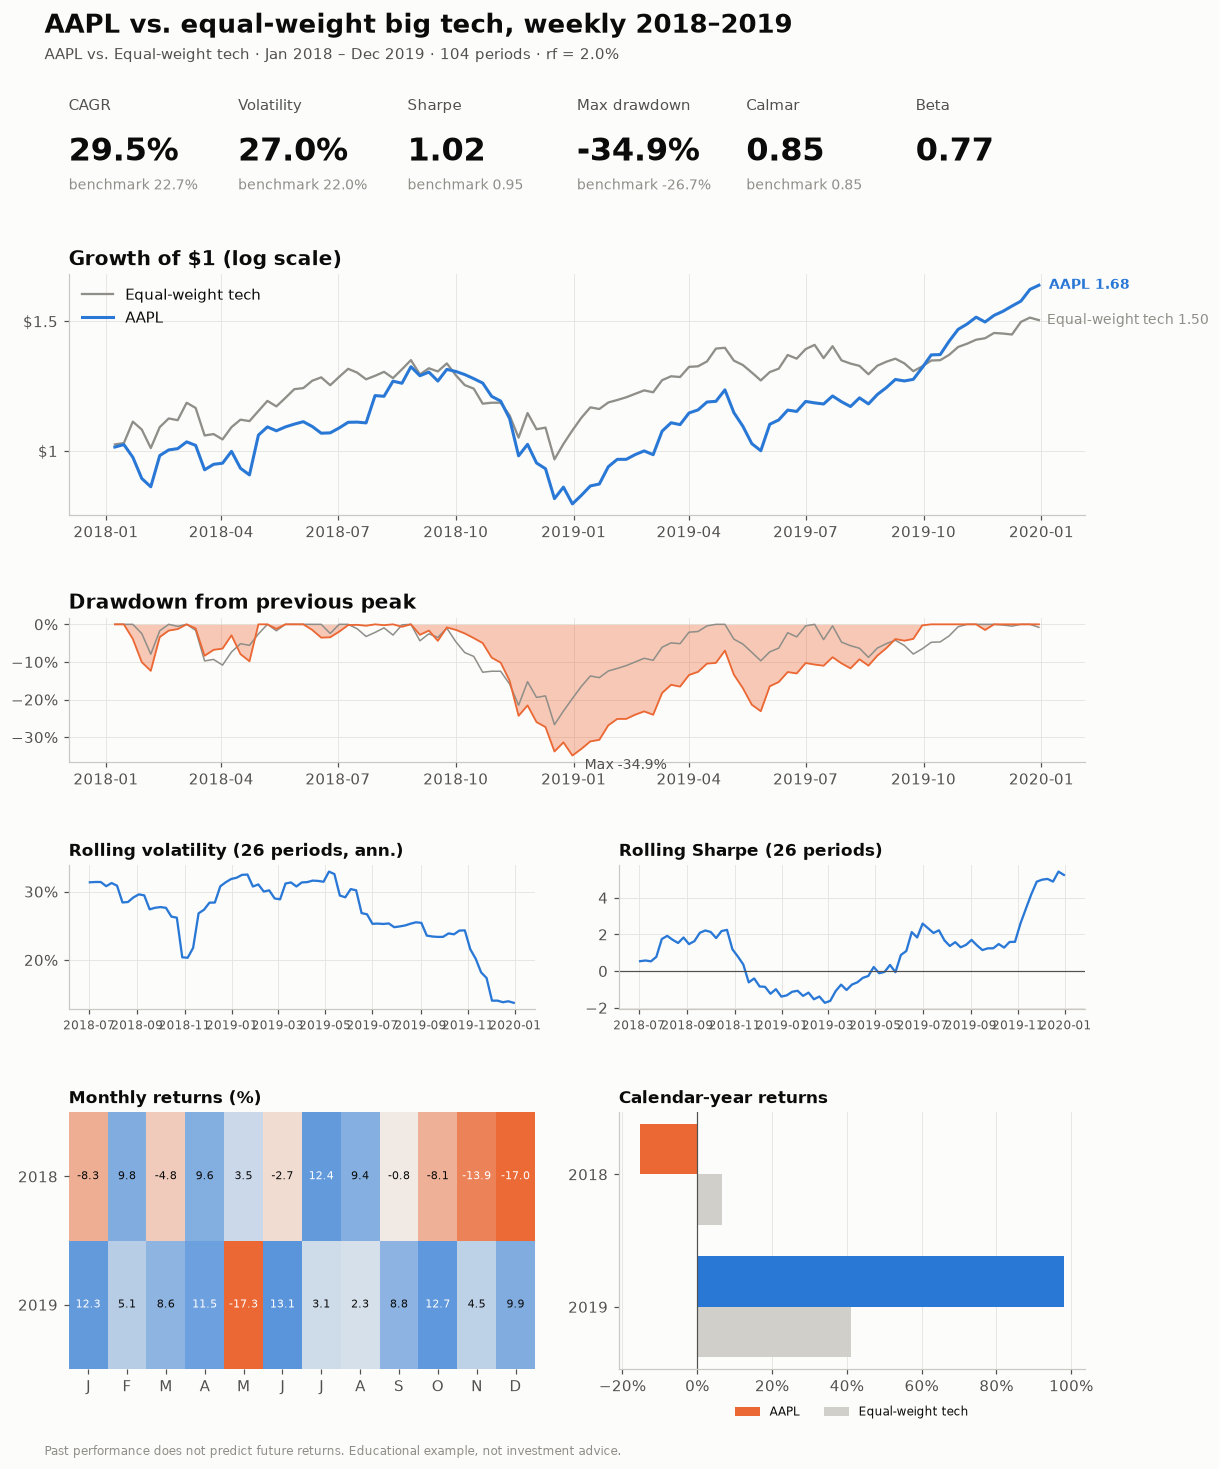

In [5]:
fig = tear_sheet(returns, benchmark, title=title, rf=0.02)
plt.show()

---
Standalone script: [`performance_tear_sheet.py`](performance_tear_sheet.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)